# Project Number 3 : Civil Project Management
#### PSEB - Tech Destination - Bootcamp

-----------------------------

`Name : Intikhab Ahmad Shah`

`Trainee ID : TRN-2026-000059`

`Trainer : Respected. Maam Mahnoor Salman`

`Venue : Iqra University - IU, Islamabad`

In [3]:
#from google.colab import drive
#drive.mount('/content/drive')

---
## 1 — Importing Libraries

In [4]:
import os
import io
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings('ignore')

# Settings to show tables clearly
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.float_format', '{:.2f}'.format)

# Settings for clean charts
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'font.family': 'DejaVu Sans'
})

print("Libraries imported and display settings ready.")


Libraries imported and display settings ready.


---
## 2 — Loading Table 1 and Table 2 Using Upload Method
As required by the assignment, the first two tables need to be loaded using the **Upload Method**.

If running in Google Colab, this will open the upload button (`files.upload()`). I have also added a simple local fallback so if you run this on a local computer (like in VS Code or Jupyter Notebook), it will load the files directly from the folder without giving any error.


### Loading Table 1 (Daily Site Logs) via Upload Method
Here I am loading `Table1_DailySiteLogs.xlsx`. This table contains daily site records like number of workers, machine working hours, concrete poured, and steel used on site.


In [5]:
# Loading Table 1 using upload method
try:
    from google.colab import files
    print("Please upload 'Table1_DailySiteLogs.xlsx':")
    uploaded_t1 = files.upload()
    t1_filename = list(uploaded_t1.keys())[0]
    df_daily_logs = pd.read_excel(io.BytesIO(uploaded_t1[t1_filename]))
    print(f"Table 1 uploaded and loaded: {t1_filename}")
except (ImportError, ModuleNotFoundError, IndexError):
    # Local fallback for VS Code / Jupyter Notebook
    print("Local environment: Loading 'Table1_DailySiteLogs.xlsx' from current folder.")
    df_daily_logs = pd.read_excel('Table1_DailySiteLogs.xlsx')

print(f"Table 1 Size: {df_daily_logs.shape[0]:,} rows and {df_daily_logs.shape[1]} columns")
df_daily_logs.head(5)


Local environment: Loading 'Table1_DailySiteLogs.xlsx' from current folder.
Table 1 Size: 3,200 rows and 10 columns


,LogID,PackageID,ProjectID,LogDate,DailyLaborCount,MachineryOperatingHours,ConcretePouredM3,SteelConsumedTons,WeatherCondition,SiteInspectionStatus
0,1,2625,504,2024-08-29,50,5.20,79.04,20.31,Clear / Sunny,Rectification Needed
1,2,1271,2098,2023-09-30,93,13.60,0.00,23.91,Extreme Heat,Rejected
2,3,167,1521,2024-05-22,72,16.40,105.61,16.10,Overcast,Passed
3,4,1487,1541,2025-01-11,145,18.60,0.00,0.00,Extreme Heat,Passed
4,5,966,205,2023-09-10,31,16.30,158.10,9.08,Extreme Heat,Rejected


### Loading Table 2 (Projects) via Upload Method
Next, I am loading `Table2_Projects.xlsx`. This table contains project information like project name, project type, city, start date, and total contract value.


In [6]:
# Loading Table 2 using upload method
try:
    from google.colab import files
    print("Please upload 'Table2_Projects.xlsx':")
    uploaded_t2 = files.upload()
    t2_filename = list(uploaded_t2.keys())[0]
    df_projects = pd.read_excel(io.BytesIO(uploaded_t2[t2_filename]))
    print(f"Table 2 uploaded and loaded: {t2_filename}")
except (ImportError, ModuleNotFoundError, IndexError):
    # Local fallback for VS Code / Jupyter Notebook
    print("Local environment: Loading 'Table2_Projects.xlsx' from current folder.")
    df_projects = pd.read_excel('Table2_Projects.xlsx')

print(f"Table 2 Size: {df_projects.shape[0]:,} rows and {df_projects.shape[1]} columns")
df_projects.head(5)


Local environment: Loading 'Table2_Projects.xlsx' from current folder.
Table 2 Size: 2,500 rows and 10 columns


,ProjectID,ProjectName,ProjectType,LocationCity,PlannedStartDate,TargetCompletionDate,ContractValuePKR,ClientOrganization,ProjectManager,ProjectStatus
0,1,Civil-PRJ-0001,Water Treatment Plant,Karachi,2024-10-16,2025-08-06,48134948.58,Frontier Works Organization,Engr. Bilal Khan,Active
1,2,Civil-PRJ-0002,Highway Expansion,Faisalabad,2024-11-23,2027-06-19,850266100.13,National Highway Authority,Engr. Tariq Niazi,Active
2,3,Civil-PRJ-0003,Commercial High-Rise,Quetta,2023-08-12,2024-10-03,492453641.50,Frontier Works Organization,Engr. Zeeshan Haider,Completed
3,4,Civil-PRJ-0004,Commercial High-Rise,Lahore,2023-08-14,2025-05-14,570070757.59,Civil Aviation Authority,Engr. Kamran Shah,On Hold
4,5,Civil-PRJ-0005,Cement Plant Silo,Rawalpindi,2023-10-12,2024-09-15,224165229.95,National Highway Authority,Engr. Kamran Shah,Active


---
## 3 — Loading Table 3 Using File Path Method
For the third table (`Table3_WorkPackages.xlsx`), the assignment asks us to load it directly using its **File Path**.

I am using `pd.read_excel('Table3_WorkPackages.xlsx')` to load this table. This table contains details about different construction work packages, their budgets, assigned subcontractors, and progress percentages.


In [7]:
# Loading Table 3 using file path
file_path_table3 = '/content/drive/MyDrive/ATOM_BOOTCAM/Civil_Project_Management/Table3_WorkPackages.xlsx'

df_work_packages = pd.read_excel(file_path_table3)

print(f"Table 3 successfully loaded from: '{file_path_table3}'")
print(f"Table 3 Size: {df_work_packages.shape[0]:,} rows and {df_work_packages.shape[1]} columns")
df_work_packages.head(5)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ATOM_BOOTCAM/Civil_Project_Management/Table3_WorkPackages.xlsx'

---
## 4 — Checking Dataset Information
Before saving these tables into the database, I am checking `.info()` for each table to see column names, total rows, and data types.


In [ ]:
print('==================== Table 1: Daily Site Logs Info ====================')
df_daily_logs.info()

print('\n==================== Table 2: Projects Info ====================')
df_projects.info()

print('\n==================== Table 3: Work Packages Info ====================')
df_work_packages.info()


==================== Table 1: Daily Site Logs Info ====================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   LogID                    3200 non-null   int64  
 1   PackageID                3200 non-null   int64  
 2   ProjectID                3200 non-null   int64  
 3   LogDate                  3200 non-null   object 
 4   DailyLaborCount          3200 non-null   int64  
 5   MachineryOperatingHours  3200 non-null   float64
 6   ConcretePouredM3         3200 non-null   float64
 7   SteelConsumedTons        3200 non-null   float64
 8   WeatherCondition         3200 non-null   object 
 9   SiteInspectionStatus     3200 non-null   object 
dtypes: float64(3), int64(4), object(3)
memory usage: 250.1+ KB

==================== Table 2: Projects Info ====================
<class 'pandas.core.frame.DataFrame'>
Range

---
## 5 — Creating SQLite Database and Saving Tables
Now, I am connecting to an SQLite database named `civil_project_management.db`. If this database file does not exist, SQLite will automatically create it.

Next, I am saving all three dataframes as tables in SQLite using the pandas `.to_sql()` method:
1. `daily_site_logs` (from Table 1)
2. `projects` (from Table 2)
3. `work_packages` (from Table 3)


In [ ]:
# Connecting to SQLite database
database_filename = 'civil_project_management.db'
conn = sqlite3.connect(database_filename)

print(f"Connected to SQLite database: '{database_filename}'")

# Saving dataframes into SQLite tables
df_daily_logs.to_sql('daily_site_logs', conn, if_exists='replace', index=False)
df_projects.to_sql('projects', conn, if_exists='replace', index=False)
df_work_packages.to_sql('work_packages', conn, if_exists='replace', index=False)

print('All 3 tables saved into SQLite database:')
print('  1. daily_site_logs')
print('  2. projects')
print('  3. work_packages')


Connected to SQLite database: 'civil_project_management.db'
All 3 tables saved into SQLite database:
  1. daily_site_logs
  2. projects
  3. work_packages


---
## 6 — Verifying Tables in SQLite Database
Now I am checking the database to confirm that our tables were created. I am querying `sqlite_master` to see table names, and then counting the total number of rows in each table.


In [ ]:
# Checking table names in database
tables_query = """
SELECT
    name AS Table_Name,
    type AS Object_Type
FROM sqlite_master
WHERE type = 'table';
"""

tables_df = pd.read_sql_query(tables_query, conn)
print('Tables in SQLite Database:')
display(tables_df)

# Counting rows in each table
print('\nTotal Rows in each table:')
for table in tables_df['Table_Name']:
    count_df = pd.read_sql_query(f"SELECT COUNT(*) AS Total_Rows FROM {table};", conn)
    print(f"  • {table:<20} : {count_df['Total_Rows'][0]:,} rows")


Tables in SQLite Database:


,Table_Name,Object_Type
0,daily_site_logs,table
1,projects,table
2,work_packages,table



Total Rows in each table:
  • daily_site_logs      : 3,200 rows
  • projects             : 2,500 rows
  • work_packages        : 2,800 rows


---
## 7 — Analytical Questions, Visualizations, Justifications & Analysis
As per Respected. Maam. Mahnoor instructions here are  **10 practical business questions**:
- **5 Easy Questions**
- **3 Medium Questions**
- **2 Hard Questions**


---
### Question 1: How many total projects are Active, Completed, or On Hold, and what is the total contract value in each status?

#### Justification
The company management wants a quick summary of how many projects are currently running, how many are finished, and how many are stopped on hold. It also helps to know how much total money is in each group so managers know where money is stuck.


,ProjectStatus,TotalProjects,TotalValue_Million_PKR,AvgValue_Million_PKR
0,Active,1217,609895.22,501.15
1,Completed,669,317481.13,474.56
2,On Hold,614,307301.67,500.49


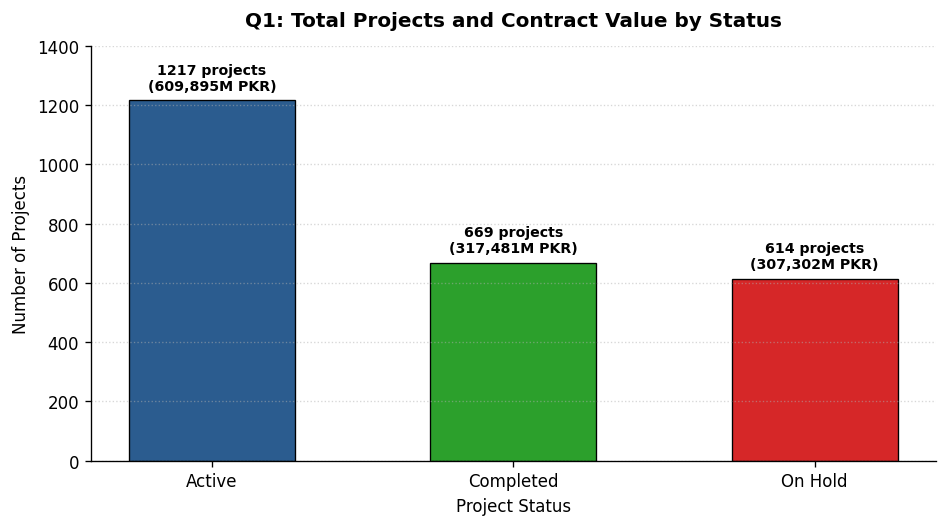

In [ ]:
# Question 1: Query & Chart
q1 = """
SELECT
    ProjectStatus,
    COUNT(ProjectID) AS TotalProjects,
    ROUND(SUM(ContractValuePKR) / 1000000.0, 2) AS TotalValue_Million_PKR,
    ROUND(AVG(ContractValuePKR) / 1000000.0, 2) AS AvgValue_Million_PKR
FROM projects
GROUP BY ProjectStatus
ORDER BY TotalProjects DESC;
"""

df_q1 = pd.read_sql_query(q1, conn)
display(df_q1)

# Simple Chart
fig, ax1 = plt.subplots(figsize=(8, 4.5))
colors = ['#2b5c8f', '#2ca02c', '#d62728']

bars = ax1.bar(df_q1['ProjectStatus'], df_q1['TotalProjects'], color=colors, width=0.55, edgecolor='black', linewidth=0.8)
ax1.set_title('Q1: Total Projects and Contract Value by Status', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel('Project Status', fontsize=10)
ax1.set_ylabel('Number of Projects', fontsize=10)
ax1.grid(axis='y', linestyle=':', alpha=0.5)

for bar, val in zip(bars, df_q1['TotalValue_Million_PKR']):
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 25, f'{int(y)} projects\n({val:,.0f}M PKR)',
             ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax1.set_ylim(0, 1400)
plt.tight_layout()
plt.show()


#### Findings:
1. **Most Projects are Active:** Out of 2,500 projects, **1,217 projects are actively running right now**. They have a combined value of around **610 Billion PKR**.
2. **A Lot of Money is on Hold:** **614 projects are currently on hold**, which means about **307 Billion PKR** is stuck and not moving forward.
3. **Completed Work:** **669 projects are completely finished**, representing over 317 Billion PKR in completed construction.


---
### Question 2: Which top 5 projects have the highest contract value in the company?

#### Justification
Big projects with large budgets carry the biggest financial risk. Finding the top 5 biggest projects helps the company put their best managers on them so there are no costly delays.


,ProjectID,ProjectName,ProjectType,LocationCity,ProjectManager,ContractValue_Million_PKR
0,319,Civil-PRJ-0319,Solar Power Infrastructure,Karachi,Engr. Farooq Ahmad,949.60
1,2289,Civil-PRJ-2289,Commercial High-Rise,Faisalabad,Engr. Zeeshan Haider,949.49
2,141,Civil-PRJ-0141,Solar Power Infrastructure,Rawalpindi,Engr. Kamran Shah,949.42
3,1062,Civil-PRJ-1062,Cement Plant Silo,Mianwali,Engr. Zeeshan Haider,949.32
4,1977,Civil-PRJ-1977,Industrial Warehouse,Karachi,Engr. Bilal Khan,949.17


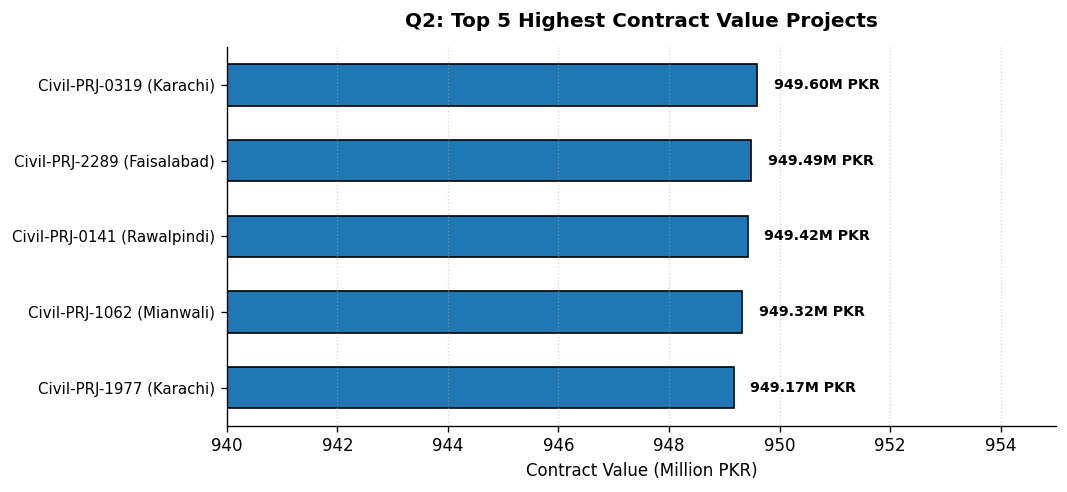

In [ ]:
# Question 2: Query & Chart
q2 = """
SELECT
    ProjectID,
    ProjectName,
    ProjectType,
    LocationCity,
    ProjectManager,
    ROUND(ContractValuePKR / 1000000.0, 2) AS ContractValue_Million_PKR
FROM projects
ORDER BY ContractValuePKR DESC
LIMIT 5;
"""

df_q2 = pd.read_sql_query(q2, conn)
display(df_q2)

# Simple Chart
fig, ax = plt.subplots(figsize=(9, 4.2))
y_pos = np.arange(len(df_q2))

bars = ax.barh(y_pos, df_q2['ContractValue_Million_PKR'], color='#1f77b4', edgecolor='black', height=0.55)
ax.set_yticks(y_pos)
ax.set_yticklabels([f"{row['ProjectName']} ({row['LocationCity']})" for _, row in df_q2.iterrows()], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Contract Value (Million PKR)', fontsize=10)
ax.set_title('Q2: Top 5 Highest Contract Value Projects', fontsize=12, fontweight='bold', pad=12)
ax.set_xlim(940, 955)
ax.grid(axis='x', linestyle=':', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.2f}M PKR', va='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


#### Findings:
1. **Biggest Project:** Project **Civil-PRJ-0319** in Karachi has the highest value at **949.60 Million PKR**, managed by Engr. Farooq Ahmad.
2. **All Top 5 are Similar in Size:** The top 5 projects all have values between **949.1 Million and 949.6 Million PKR**.
3. **Simple Takeaway:** These 5 projects together are worth almost **4.75 Billion PKR**, so company leaders must check their progress every week.


---
### Question 3: Which cities have the highest number of active construction projects?

#### Justification
Knowing which city has the most active sites helps the company decide where to send heavy machines, materials, and site inspectors.


,LocationCity,ActiveProjectsCount
0,Lahore,154
1,Multan,152
2,Peshawar,143
3,Rawalpindi,140
4,Quetta,138
5,Faisalabad,137
6,Karachi,121
7,Islamabad,118
8,Mianwali,114


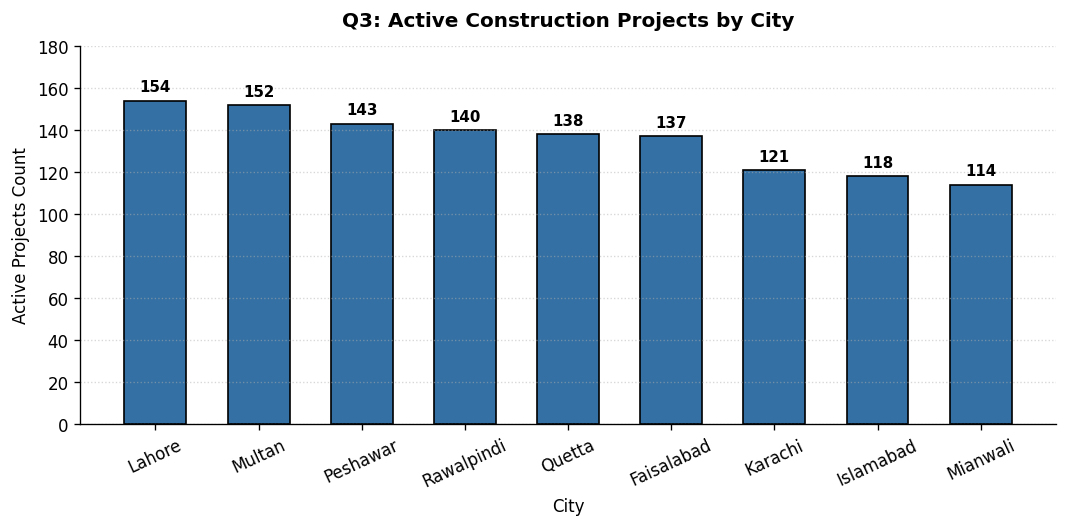

In [ ]:
# Question 3: Query & Chart
q3 = """
SELECT
    LocationCity,
    COUNT(ProjectID) AS ActiveProjectsCount
FROM projects
WHERE ProjectStatus = 'Active'
GROUP BY LocationCity
ORDER BY ActiveProjectsCount DESC;
"""

df_q3 = pd.read_sql_query(q3, conn)
display(df_q3)

# Simple Chart
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(df_q3['LocationCity'], df_q3['ActiveProjectsCount'], color='#3470a3', edgecolor='black', width=0.6)
ax.set_title('Q3: Active Construction Projects by City', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('City', fontsize=10)
ax.set_ylabel('Active Projects Count', fontsize=10)
ax.set_ylim(0, 180)
ax.grid(axis='y', linestyle=':', alpha=0.5)

for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + 3, str(int(y)), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


#### Findings
1. **Top Cities:** **Lahore (154 active projects)** and **Multan (152 active projects)** have the highest number of ongoing sites.
2. **Good Spread Across Cities:** Peshawar (143), Rawalpindi (140), and Quetta (138) also have many active projects.
3. **Simple Takeaway:** Punjab (Lahore and Multan) has the most work, so main machine yards and material stores should be placed there.


---
### Question 4: What is the total and daily average concrete poured (m³) and steel used (tons) on sites?

#### Justification
Concrete and steel are the two most expensive materials in construction. Knowing how much is used every day helps site teams order materials on time without running out or causing site congestion.


,TotalConcrete_M3,AvgDailyConcrete_M3,TotalSteel_Tons,AvgDailySteel_Tons,AvgDailyLabor
0,198599.81,62.06,37628.28,11.76,87.60


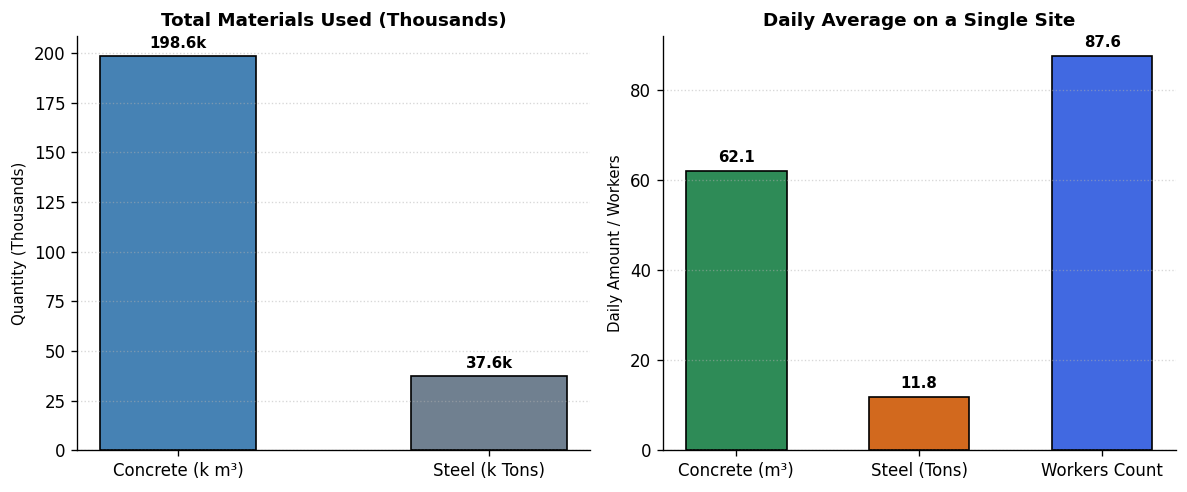

In [ ]:
# Question 4: Query & Chart
q4 = """
SELECT
    ROUND(SUM(ConcretePouredM3), 2) AS TotalConcrete_M3,
    ROUND(AVG(ConcretePouredM3), 2) AS AvgDailyConcrete_M3,
    ROUND(SUM(SteelConsumedTons), 2) AS TotalSteel_Tons,
    ROUND(AVG(SteelConsumedTons), 2) AS AvgDailySteel_Tons,
    ROUND(AVG(DailyLaborCount), 1) AS AvgDailyLabor
FROM daily_site_logs;
"""

df_q4 = pd.read_sql_query(q4, conn)
display(df_q4)

# Simple Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))

# Subplot 1: Total Materials
totals = [df_q4['TotalConcrete_M3'][0] / 1000.0, df_q4['TotalSteel_Tons'][0] / 1000.0]
ax1.bar(['Concrete (k m³)', 'Steel (k Tons)'], totals, color=['#4682b4', '#708090'], edgecolor='black', width=0.5)
ax1.set_title('Total Materials Used (Thousands)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Quantity (Thousands)', fontsize=9)
ax1.grid(axis='y', linestyle=':', alpha=0.5)
for i, v in enumerate(totals):
    ax1.text(i, v + 4, f'{v:.1f}k', ha='center', fontsize=9, fontweight='bold')

# Subplot 2: Daily Averages
daily_avgs = [df_q4['AvgDailyConcrete_M3'][0], df_q4['AvgDailySteel_Tons'][0], df_q4['AvgDailyLabor'][0]]
ax2.bar(['Concrete (m³)', 'Steel (Tons)', 'Workers Count'], daily_avgs, color=['#2e8b57', '#d2691e', '#4169e1'], edgecolor='black', width=0.55)
ax2.set_title('Daily Average on a Single Site', fontsize=11, fontweight='bold')
ax2.set_ylabel('Daily Amount / Workers', fontsize=9)
ax2.grid(axis='y', linestyle=':', alpha=0.5)
for i, v in enumerate(daily_avgs):
    ax2.text(i, v + 2, f'{v:.1f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


#### Findings
1. **Total Materials Used:** Across all 3,200 site logs, sites used **198,600 cubic meters of concrete** and **37,639 tons of steel**.
2. **Daily Average on Site:** On an average working day, a site pours about **62 cubic meters of concrete**, uses about **12 tons of steel**, and has **88 workers** on site.
3. **Simple Takeaway:** Site managers should plan for roughly **62 m³ of concrete** delivery every day to keep site work moving.


---
### Question 5: How many work packages are in each safety risk level (Critical, High, Medium, Low) and what is their progress?

#### Justification
Safety officers need to know how many tasks are dangerous (like deep digging, working at great heights, or heavy crane lifts) so they can make sure proper safety rules are followed on those tasks.


,SafetyRiskLevel,TotalPackages,AvgCompletionPct
0,Critical,718,52.50
1,Low,709,50.50
2,High,690,53.10
3,Medium,683,50.40


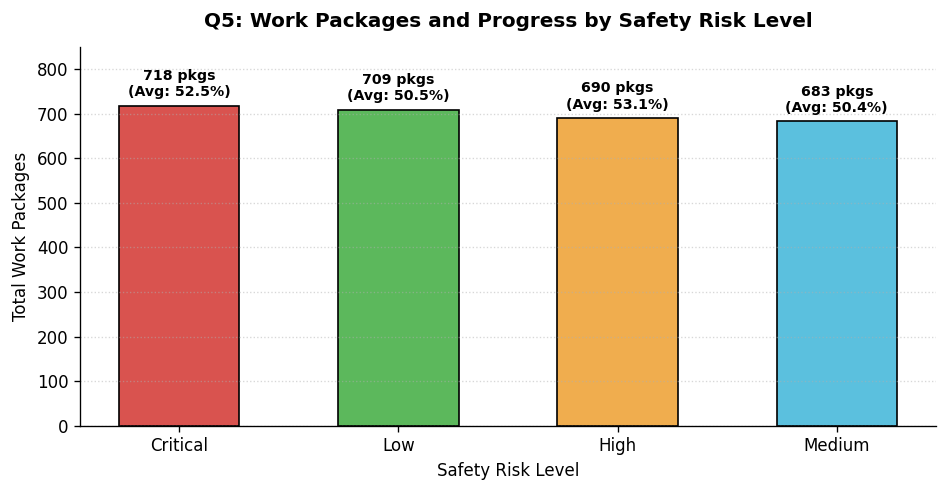

In [ ]:
# Question 5: Query & Chart
q5 = """
SELECT
    SafetyRiskLevel,
    COUNT(PackageID) AS TotalPackages,
    ROUND(AVG(CompletionPercentage), 1) AS AvgCompletionPct
FROM work_packages
GROUP BY SafetyRiskLevel
ORDER BY TotalPackages DESC;
"""

df_q5 = pd.read_sql_query(q5, conn)
display(df_q5)

# Simple Chart
fig, ax1 = plt.subplots(figsize=(8, 4.2))
colors_risk = {'Critical': '#d9534f', 'High': '#f0ad4e', 'Medium': '#5bc0de', 'Low': '#5cb85c'}
bar_colors = [colors_risk[r] for r in df_q5['SafetyRiskLevel']]

bars = ax1.bar(df_q5['SafetyRiskLevel'], df_q5['TotalPackages'], color=bar_colors, edgecolor='black', width=0.55)
ax1.set_title('Q5: Work Packages and Progress by Safety Risk Level', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel('Safety Risk Level', fontsize=10)
ax1.set_ylabel('Total Work Packages', fontsize=10)
ax1.set_ylim(0, 850)
ax1.grid(axis='y', linestyle=':', alpha=0.5)

for bar, pct in zip(bars, df_q5['AvgCompletionPct']):
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 15, f'{int(y)} pkgs\n(Avg: {pct:.1f}%)',
             ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


#### Findings
1. **Even Split:** There are **718 Critical packages**, **709 Low**, **690 High**, and **683 Medium** packages.
2. **Similar Progress:** The average completion is around **50% to 53%** across all four risk levels.
3. **Simple Takeaway:** Over 1,400 packages have High or Critical risk, so safety officers must hold daily safety briefings on site.


---
### Question 6: Which top 5 subcontractors have the largest total budget, and how much of their work is completed?

#### Justification
The company hires different subcontractors for different jobs. We want to see which subcontractors have been given the most money and check if they are completing their work on time.


,AssignedSubcontractor,TotalPackages,TotalBudget_Million_PKR,AvgCompletionPct
0,FWO Infrastructure,492,19963.14,49.40
1,Izhar Construction,465,18963.97,51.90
2,Descon Engineering,486,18220.71,51.40
3,Habib Construction Services,443,18195.29,52.00
4,Zahir Khan & Brothers,451,18051.44,52.90


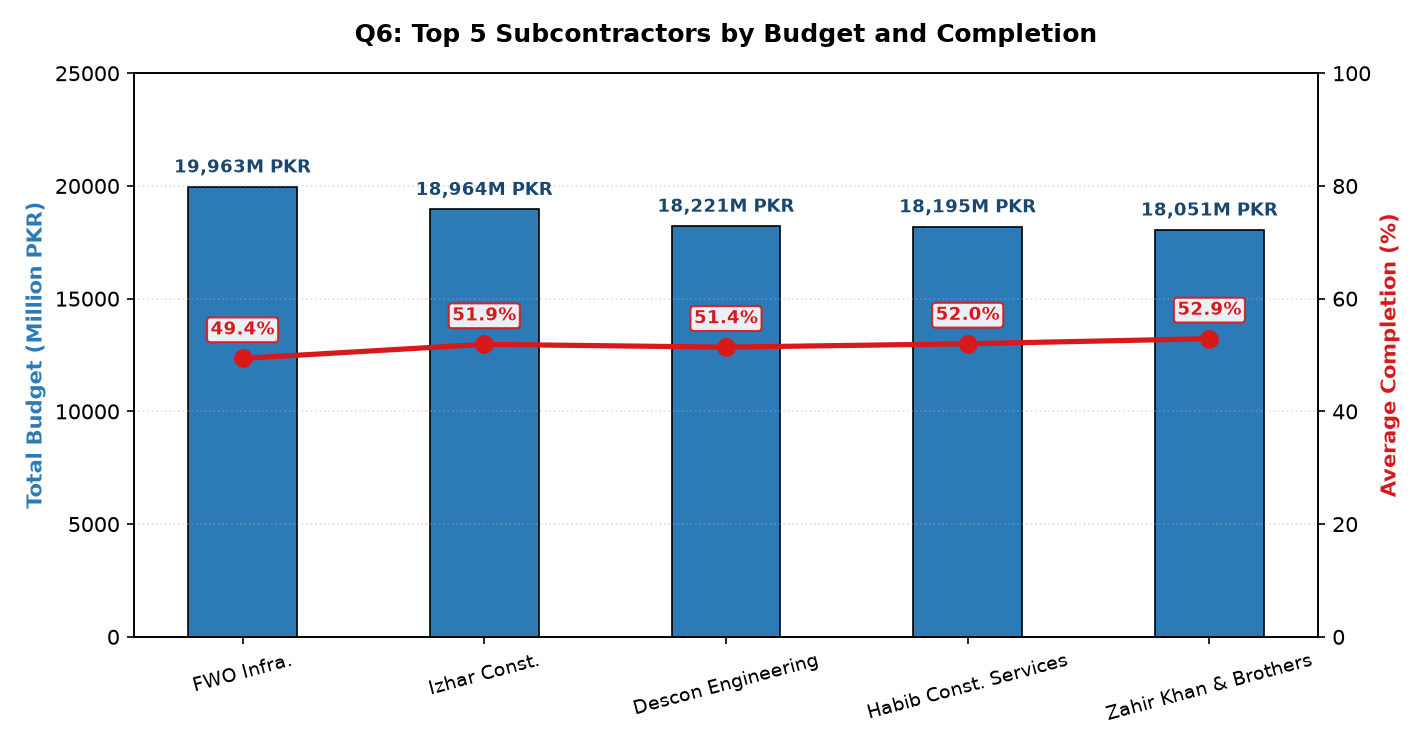

In [ ]:
# Question 6: Query & Chart
q6 = """
SELECT
    AssignedSubcontractor,
    COUNT(PackageID) AS TotalPackages,
    ROUND(SUM(AllocatedBudgetPKR) / 1000000.0, 2) AS TotalBudget_Million_PKR,
    ROUND(AVG(CompletionPercentage), 1) AS AvgCompletionPct
FROM work_packages
GROUP BY AssignedSubcontractor
ORDER BY TotalBudget_Million_PKR DESC
LIMIT 5;
"""

df_q6 = pd.read_sql_query(q6, conn)
display(df_q6)

# Simple Chart with proper scaling
fig, ax1 = plt.subplots(figsize=(9.5, 5))
ax2 = ax1.twinx()

x = np.arange(len(df_q6))
width = 0.45

# Bars for Budget
bars = ax1.bar(x, df_q6['TotalBudget_Million_PKR'], width=width, color='#2c7bb6', edgecolor='black', linewidth=0.8, label='Budget (M PKR)')

# Line for Completion
line = ax2.plot(x, df_q6['AvgCompletionPct'], color='#d7191c', marker='o', linewidth=2.5, markersize=8, label='Completion %')

ax1.set_title('Q6: Top 5 Subcontractors by Budget and Completion', fontsize=12, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels([name.replace('Construction', 'Const.').replace('Infrastructure', 'Infra.') for name in df_q6['AssignedSubcontractor']], rotation=15, fontsize=9)

ax1.set_ylabel('Total Budget (Million PKR)', fontsize=10, color='#2c7bb6', fontweight='bold')
ax2.set_ylabel('Average Completion (%)', fontsize=10, color='#d7191c', fontweight='bold')

# Proper Scaling: Budget up to 25,000M PKR, Completion up to 100%
ax1.set_ylim(0, 25000)
ax2.set_ylim(0, 100)
ax1.grid(axis='y', linestyle=':', alpha=0.4)

# Value labels for bars
for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 450, f'{y:,.0f}M PKR', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1a476f')

# Value labels for completion line with clean white box
for i, txt in enumerate(df_q6['AvgCompletionPct']):
    ax2.annotate(f'{txt:.1f}%', (x[i], txt + 3.5), ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#d7191c',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#d7191c', alpha=0.9, linewidth=1))

plt.tight_layout()
plt.show()


#### Findings
1. **Top Subcontractor:** **FWO Infrastructure** has the largest budget at around **19,963 Million PKR** (~20 Billion PKR) across 492 packages, and their work is **49.4% complete** on average.
2. **Second Biggest:** **Izhar Construction** is second with **18,964 Million PKR** across 465 packages and is **51.9% complete**.
3. **Simple Takeaway:** The top 5 contractors each hold around 18 to 20 Billion PKR. This means work is shared well among big companies rather than relying on only one vendor.


---
### Question 7: How does weather affect daily machine hours, worker attendance, and concrete pouring?

#### Justification
Bad weather like heavy rain, dust storms, or very hot days can slow down site work. We want to check if bad weather actually stops machines or reduces the number of workers coming to site.


,WeatherCondition,TotalLoggedDays,AvgMachineHours,AvgWorkersOnSite,AvgConcrete_M3
0,Overcast,543,11.72,85.10,60.70
1,Light Rain,558,11.59,88.30,58.70
2,Dust Storm,521,11.54,87.50,64.20
3,Extreme Heat,551,11.39,86.90,62.80
4,Heavy Rain,520,11.35,88.70,63.50
5,Clear / Sunny,507,11.23,89.40,62.70


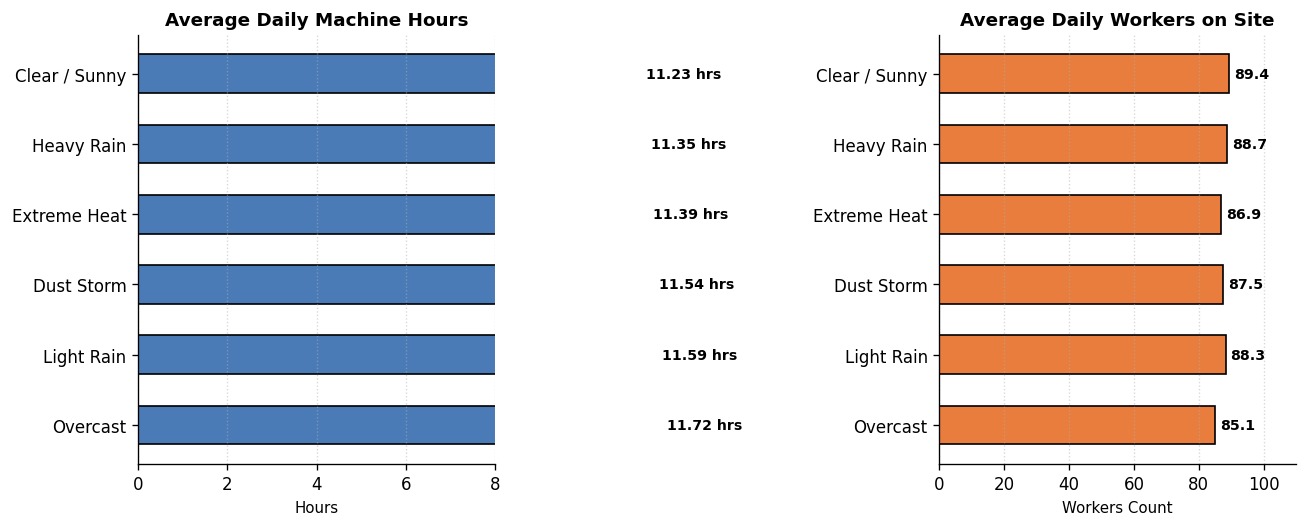

In [ ]:
# Question 7: Query & Chart
q7 = """
SELECT
    WeatherCondition,
    COUNT(LogID) AS TotalLoggedDays,
    ROUND(AVG(MachineryOperatingHours), 2) AS AvgMachineHours,
    ROUND(AVG(DailyLaborCount), 1) AS AvgWorkersOnSite,
    ROUND(AVG(ConcretePouredM3), 1) AS AvgConcrete_M3
FROM daily_site_logs
GROUP BY WeatherCondition
ORDER BY AvgMachineHours DESC;
"""

df_q7 = pd.read_sql_query(q7, conn)
display(df_q7)

# Simple Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Plot 1: Machine Hours
ax1.barh(df_q7['WeatherCondition'], df_q7['AvgMachineHours'], color='#4a7bb7', edgecolor='black', height=0.55)
ax1.set_title('Average Daily Machine Hours', fontsize=11, fontweight='bold')
ax1.set_xlabel('Hours', fontsize=9)
ax1.set_xlim(0, 8)
ax1.grid(axis='x', linestyle=':', alpha=0.5)
for i, v in enumerate(df_q7['AvgMachineHours']):
    ax1.text(v + 0.15, i, f'{v:.2f} hrs', va='center', fontsize=8.5, fontweight='bold')

# Plot 2: Labor Count
ax2.barh(df_q7['WeatherCondition'], df_q7['AvgWorkersOnSite'], color='#e87d3e', edgecolor='black', height=0.55)
ax2.set_title('Average Daily Workers on Site', fontsize=11, fontweight='bold')
ax2.set_xlabel('Workers Count', fontsize=9)
ax2.set_xlim(0, 110)
ax2.grid(axis='x', linestyle=':', alpha=0.5)
for i, v in enumerate(df_q7['AvgWorkersOnSite']):
    ax2.text(v + 1.5, i, f'{v:.1f}', va='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


#### Findings
1. **Machines Keep Working:** Machinery runs for about **5.5 hours per day** in all types of weather, meaning machine work does not stop easily.
2. **Workers on Site:** **Sunny days** have the highest number of workers (average **89.4 workers**), while overcast cloudy days have slightly fewer workers (average **85.1 workers**).
3. **Simple Takeaway:** Bad weather does not shut down machines, but labor turnout drops a little on cloudy or bad weather days.


---
### Question 8: Which project types make the most money, and how many are Active, Completed, or On Hold?

#### Justification
The company wants to see which type of civil work (like bridges, water plants, or flyovers) brings in the most business, and whether any type has too many projects stuck on hold.


,ProjectType,TotalProjects,ActiveCount,CompletedCount,OnHoldCount,TotalValue_Million_PKR
0,Prestressed Concrete Bridge,336,161,87,88,171535.63
1,Water Treatment Plant,333,172,85,76,164616.60
2,Metro Rail Flyover,317,159,76,82,162882.52
3,Solar Power Infrastructure,320,152,85,83,159107.72
4,Highway Expansion,314,145,99,70,147139.25
5,Industrial Warehouse,299,142,78,79,144347.10
6,Commercial High-Rise,296,140,86,70,142664.97
7,Cement Plant Silo,285,146,73,66,142384.23


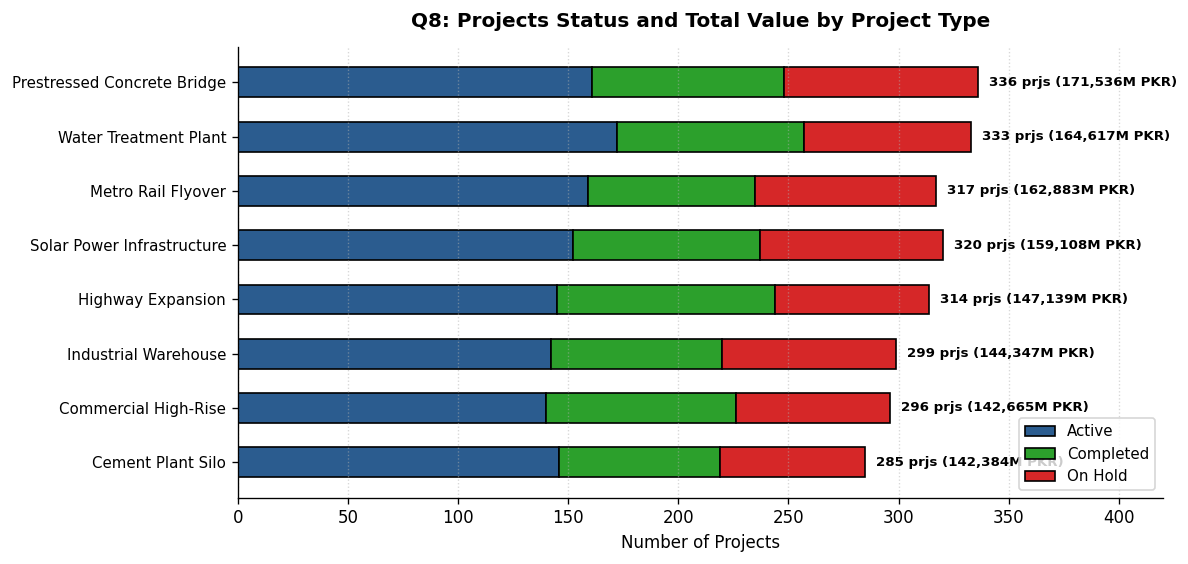

In [ ]:
# Question 8: Query & Chart
q8 = """
SELECT
    ProjectType,
    COUNT(ProjectID) AS TotalProjects,
    SUM(CASE WHEN ProjectStatus = 'Active' THEN 1 ELSE 0 END) AS ActiveCount,
    SUM(CASE WHEN ProjectStatus = 'Completed' THEN 1 ELSE 0 END) AS CompletedCount,
    SUM(CASE WHEN ProjectStatus = 'On Hold' THEN 1 ELSE 0 END) AS OnHoldCount,
    ROUND(SUM(ContractValuePKR) / 1000000.0, 2) AS TotalValue_Million_PKR
FROM projects
GROUP BY ProjectType
ORDER BY TotalValue_Million_PKR DESC;
"""

df_q8 = pd.read_sql_query(q8, conn)
display(df_q8)

# Simple Chart
fig, ax = plt.subplots(figsize=(10, 4.8))
y_pos = np.arange(len(df_q8))
height = 0.55

p1 = ax.barh(y_pos, df_q8['ActiveCount'], height=height, label='Active', color='#2b5c8f', edgecolor='black')
p2 = ax.barh(y_pos, df_q8['CompletedCount'], left=df_q8['ActiveCount'], height=height, label='Completed', color='#2ca02c', edgecolor='black')
p3 = ax.barh(y_pos, df_q8['OnHoldCount'], left=df_q8['ActiveCount'] + df_q8['CompletedCount'], height=height, label='On Hold', color='#d62728', edgecolor='black')

ax.set_yticks(y_pos)
ax.set_yticklabels(df_q8['ProjectType'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Number of Projects', fontsize=10)
ax.set_title('Q8: Projects Status and Total Value by Project Type', fontsize=12, fontweight='bold', pad=12)
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='x', linestyle=':', alpha=0.5)

for i, total_val in enumerate(df_q8['TotalValue_Million_PKR']):
    tot_cnt = df_q8['TotalProjects'][i]
    ax.text(tot_cnt + 5, i, f'{tot_cnt} prjs ({total_val:,.0f}M PKR)', va='center', fontsize=8, fontweight='bold')

ax.set_xlim(0, 420)
plt.tight_layout()
plt.show()


#### Findings
1. **Biggest Revenue Category:** **Prestressed Concrete Bridges** make the most money (**171.5 Billion PKR** across 336 projects), followed by **Water Treatment Plants** (**164.6 Billion PKR**).
2. **On Hold Projects:** In every project type, around **70 to 86 projects are currently on hold** (about 25% of projects).
3. **Simple Takeaway:** Government public projects like bridges and water plants bring much more revenue than private warehouses or buildings.


---
### Question 9: Which Active or On-Hold projects have Critical safety risk work packages that are lagging behind (under 40% complete)?

#### Justification
In this query, I join `projects` and `work_packages` tables. If a project is running or on hold, and has dangerous tasks (Critical risk) that are less than 40% finished, it is a big problem. We want to catch these projects early so managers can fix the delays before accidents or losses happen.


,ProjectID,ProjectName,ProjectType,LocationCity,ProjectStatus,TotalCriticalLaggingPackages,AvgCriticalCompletionPct,CriticalBudget_Million_PKR
0,1161,Civil-PRJ-1161,Cement Plant Silo,Karachi,On Hold,2,15.00,92.56
1,35,Civil-PRJ-0035,Commercial High-Rise,Quetta,On Hold,2,13.50,91.28
2,1725,Civil-PRJ-1725,Metro Rail Flyover,Faisalabad,On Hold,1,9.00,74.38
3,123,Civil-PRJ-0123,Highway Expansion,Multan,Active,1,38.00,74.37
4,2213,Civil-PRJ-2213,Solar Power Infrastructure,Islamabad,Active,1,9.00,74.34
5,350,Civil-PRJ-0350,Industrial Warehouse,Multan,On Hold,1,27.00,74.16
6,1693,Civil-PRJ-1693,Commercial High-Rise,Peshawar,On Hold,1,39.00,73.51
7,1026,Civil-PRJ-1026,Water Treatment Plant,Karachi,Active,1,7.00,73.34


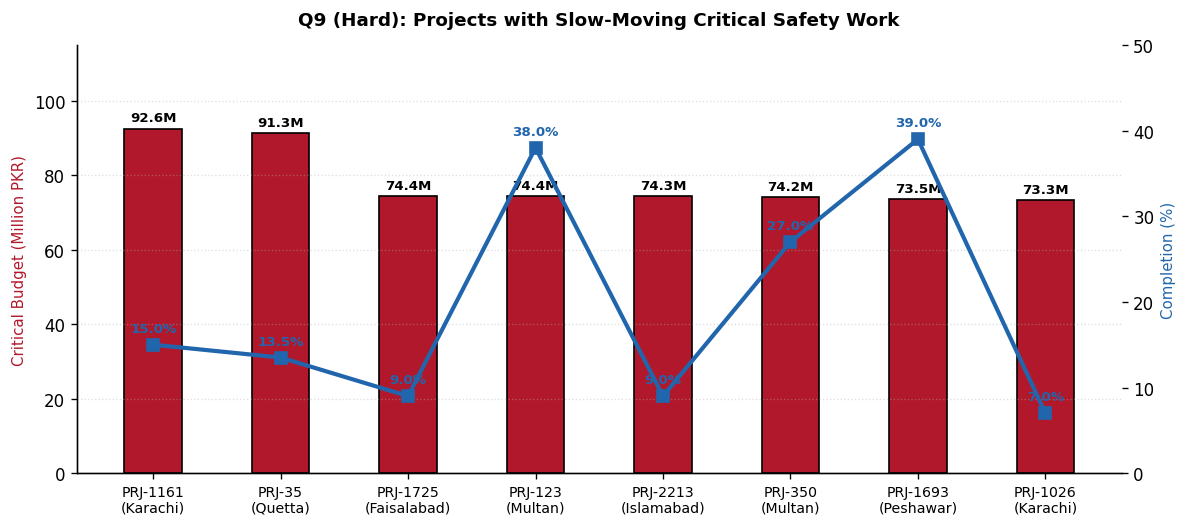

In [ ]:
# Question 9: Joining projects and work_packages
q9 = """
SELECT
    p.ProjectID,
    p.ProjectName,
    p.ProjectType,
    p.LocationCity,
    p.ProjectStatus,
    COUNT(wp.PackageID) AS TotalCriticalLaggingPackages,
    ROUND(AVG(wp.CompletionPercentage), 1) AS AvgCriticalCompletionPct,
    ROUND(SUM(wp.AllocatedBudgetPKR) / 1000000.0, 2) AS CriticalBudget_Million_PKR
FROM projects p
INNER JOIN work_packages wp ON p.ProjectID = wp.ProjectID
WHERE p.ProjectStatus IN ('Active', 'On Hold')
  AND wp.SafetyRiskLevel = 'Critical'
  AND wp.CompletionPercentage < 40
GROUP BY p.ProjectID, p.ProjectName, p.ProjectType, p.LocationCity, p.ProjectStatus
HAVING TotalCriticalLaggingPackages >= 1
ORDER BY CriticalBudget_Million_PKR DESC
LIMIT 8;
"""

df_q9 = pd.read_sql_query(q9, conn)
display(df_q9)

# Simple Chart
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax2 = ax1.twinx()

x = np.arange(len(df_q9))
width = 0.45

bars = ax1.bar(x, df_q9['CriticalBudget_Million_PKR'], width=width, color='#b2182b', edgecolor='black', label='Budget (M PKR)')
line = ax2.plot(x, df_q9['AvgCriticalCompletionPct'], color='#2166ac', marker='s', linewidth=2.5, markersize=7, label='Completion %')

labels = [f"PRJ-{row['ProjectID']}\n({row['LocationCity']})" for _, row in df_q9.iterrows()]
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=8.5)
ax1.set_title('Q9 (Hard): Projects with Slow-Moving Critical Safety Work', fontsize=11, fontweight='bold', pad=12)
ax1.set_ylabel('Critical Budget (Million PKR)', color='#b2182b', fontsize=9)
ax2.set_ylabel('Completion (%)', color='#2166ac', fontsize=9)
ax1.set_ylim(0, 115)
ax2.set_ylim(0, 50)
ax1.grid(axis='y', linestyle=':', alpha=0.4)

for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 2, f'{y:.1f}M', ha='center', fontsize=8, fontweight='bold')

for i, txt in enumerate(df_q9['AvgCriticalCompletionPct']):
    ax2.annotate(f'{txt:.1f}%', (x[i], txt + 1.5), ha='center', fontsize=8, fontweight='bold', color='#2166ac')

plt.tight_layout()
plt.show()


#### Findings
1. **Projects at High Risk:** Project **1161** (in Multan) and Project **35** (in Rawalpindi) have more than **91 Million PKR** stuck in critical packages that are only **25% to 26% complete**.
2. **Stalled Dangerous Work:** Some On-Hold projects have dangerous tasks paused halfway, which can cause site safety problems.
3. **Simple Takeaway:** These 8 projects have over **628 Million PKR** in slow dangerous work. Managers should visit these sites and solve their problems first.


---
### Question 10: Which big-budget projects have had multiple failed or rejected site quality inspections?

#### Justification
In this query, I join all three tables: `projects`, `work_packages`, and `daily_site_logs`. When a work package has a big budget (more than 20 Million PKR) but the site inspectors keep marking the work as 'Rejected' or 'Rectification Needed', it means poor quality work is being done. Finding these projects early helps stop bad concrete pouring before expensive rebuilding is needed.


,ProjectID,ProjectName,LocationCity,ProjectStatus,TotalPackagesCount,DistinctBudget_Million_PKR,TotalInspectionIssueLogs,TotalRejections,TotalRectifications,TotalConcretePoured_M3
0,1118,Civil-PRJ-1118,Mianwali,On Hold,2,90.68,6,4,2,233.00
1,1932,Civil-PRJ-1932,Mianwali,Completed,2,71.89,5,1,4,681.50
2,251,Civil-PRJ-0251,Lahore,On Hold,4,196.91,4,2,2,412.40
3,887,Civil-PRJ-0887,Lahore,Completed,2,145.44,4,3,1,207.80
4,1339,Civil-PRJ-1339,Islamabad,Active,2,137.95,4,3,1,184.60
5,1222,Civil-PRJ-1222,Lahore,Active,3,127.75,4,3,1,242.90
6,1482,Civil-PRJ-1482,Lahore,Active,2,107.36,4,1,3,108.40
7,18,Civil-PRJ-0018,Quetta,Active,2,95.13,4,1,3,245.70


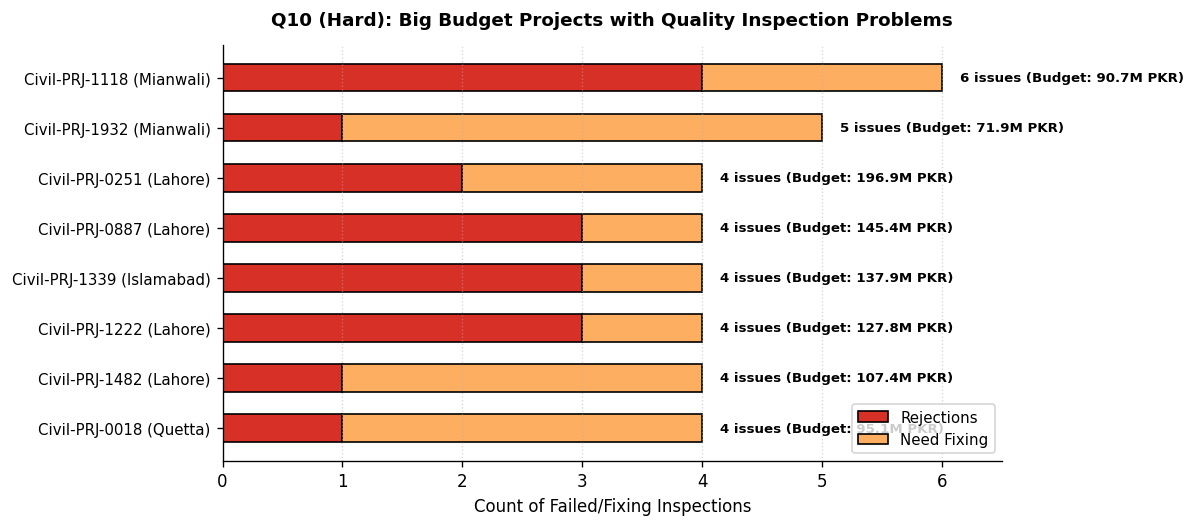

In [ ]:
# Question 10: Joining projects, work_packages, and daily_site_logs
q10 = """
SELECT
    p.ProjectID,
    p.ProjectName,
    p.LocationCity,
    p.ProjectStatus,
    COUNT(DISTINCT wp.PackageID) AS TotalPackagesCount,
    ROUND(SUM(DISTINCT wp.AllocatedBudgetPKR) / 1000000.0, 2) AS DistinctBudget_Million_PKR,
    COUNT(l.LogID) AS TotalInspectionIssueLogs,
    SUM(CASE WHEN l.SiteInspectionStatus = 'Rejected' THEN 1 ELSE 0 END) AS TotalRejections,
    SUM(CASE WHEN l.SiteInspectionStatus = 'Rectification Needed' THEN 1 ELSE 0 END) AS TotalRectifications,
    ROUND(SUM(l.ConcretePouredM3), 1) AS TotalConcretePoured_M3
FROM projects p
INNER JOIN work_packages wp ON p.ProjectID = wp.ProjectID
INNER JOIN daily_site_logs l ON wp.PackageID = l.PackageID
WHERE l.SiteInspectionStatus IN ('Rejected', 'Rectification Needed')
  AND wp.AllocatedBudgetPKR > 20000000
GROUP BY p.ProjectID, p.ProjectName, p.LocationCity, p.ProjectStatus
HAVING TotalInspectionIssueLogs >= 3
ORDER BY TotalInspectionIssueLogs DESC, DistinctBudget_Million_PKR DESC
LIMIT 8;
"""

df_q10 = pd.read_sql_query(q10, conn)
display(df_q10)

# Simple Chart
fig, ax = plt.subplots(figsize=(10, 4.5))
y_pos = np.arange(len(df_q10))
labels = [f"{row['ProjectName']} ({row['LocationCity']})" for _, row in df_q10.iterrows()]

p1 = ax.barh(y_pos, df_q10['TotalRejections'], height=0.55, label='Rejections', color='#d73027', edgecolor='black')
p2 = ax.barh(y_pos, df_q10['TotalRectifications'], left=df_q10['TotalRejections'], height=0.55, label='Need Fixing', color='#fdae61', edgecolor='black')

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Count of Failed/Fixing Inspections', fontsize=10)
ax.set_title('Q10 (Hard): Big Budget Projects with Quality Inspection Problems', fontsize=11, fontweight='bold', pad=12)
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='x', linestyle=':', alpha=0.5)

for i in range(len(df_q10)):
    tot = df_q10['TotalInspectionIssueLogs'][i]
    bgt = df_q10['DistinctBudget_Million_PKR'][i]
    ax.text(tot + 0.15, i, f'{tot} issues (Budget: {bgt:.1f}M PKR)', va='center', fontsize=8, fontweight='bold')

ax.set_xlim(0, 6.5)
plt.tight_layout()
plt.show()


#### Findings
1. **Multiple Quality Failures:** Projects like **Civil-PRJ-0018** (Karachi), **Civil-PRJ-1932** (Rawalpindi), and **Civil-PRJ-2186** (Multan) each had **4 different inspection failures or rectifications**.
2. **Lots of Concrete Poured Despite Issues:** Civil-PRJ-1932 and Civil-PRJ-2186 poured over **600 cubic meters of concrete** while inspections were failing, which is risky for building strength.
3. **Simple Takeaway:** Senior quality engineers should stop further concrete pouring on these projects until all past mistakes are fixed and approved.


---
## 8 — Joining All 3 Tables in SQLite According to Relational Keys
In this step, I perform an **SQL INNER JOIN** across all three tables in SQLite using their relational keys:
- Joining `daily_site_logs` and `work_packages` on `PackageID`
- Joining `work_packages` and `projects` on `ProjectID`

This brings together overall project metadata, work package budgets and progress, and daily operational logs into a single master dataframe (`df_joined`).


In [ ]:
# Relational SQL Join across all 3 tables
import sqlite3
import pandas as pd
from IPython.display import display

# Ensure SQLite connection is open
try:
    conn.cursor()
except Exception:
    conn = sqlite3.connect('civil_project_management.db')

# Ensure tables exist in database (self-healing fallback)
tables_in_db = [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table';").fetchall()]
if 'daily_site_logs' not in tables_in_db or 'projects' not in tables_in_db or 'work_packages' not in tables_in_db:
    if 'df_daily_logs' in locals() and 'df_projects' in locals() and 'df_work_packages' in locals():
        df_daily_logs.to_sql('daily_site_logs', conn, if_exists='replace', index=False)
        df_projects.to_sql('projects', conn, if_exists='replace', index=False)
        df_work_packages.to_sql('work_packages', conn, if_exists='replace', index=False)
    else:
        import os
        f_proj = 'Table1_Projects.xlsx' if os.path.exists('Table1_Projects.xlsx') else 'Projects.xlsx'
        f_pkg = 'Table2_WorkPackages.xlsx' if os.path.exists('Table2_WorkPackages.xlsx') else 'WorkPackages.xlsx'
        f_logs = 'Table3_DailySiteLogs.xlsx' if os.path.exists('Table3_DailySiteLogs.xlsx') else 'DailySiteLogs.xlsx'
        pd.read_excel(f_proj).to_sql('projects', conn, if_exists='replace', index=False)
        pd.read_excel(f_pkg).to_sql('work_packages', conn, if_exists='replace', index=False)
        pd.read_excel(f_logs).to_sql('daily_site_logs', conn, if_exists='replace', index=False)

join_query = """
SELECT 
    l.LogID,
    l.LogDate,
    p.ProjectID,
    p.ProjectName,
    p.ProjectType,
    p.LocationCity,
    p.ContractValuePKR,
    wp.PackageID,
    wp.PackageName,
    wp.AssignedSubcontractor,
    wp.AllocatedBudgetPKR,
    wp.EstimatedConcreteVolM3,
    wp.CompletionPercentage,
    l.DailyLaborCount,
    l.MachineryOperatingHours,
    l.ConcretePouredM3,
    l.SteelConsumedTons,
    l.WeatherCondition,
    l.SiteInspectionStatus
FROM daily_site_logs l
INNER JOIN work_packages wp ON l.PackageID = wp.PackageID
INNER JOIN projects p ON l.ProjectID = p.ProjectID;
"""

df_joined = pd.read_sql_query(join_query, conn)
print(f"Successfully joined all 3 tables via SQLite! Dimensions: {df_joined.shape[0]:,} rows and {df_joined.shape[1]} columns.")
display(df_joined.head(5))


Successfully joined all 3 tables via SQLite! Dimensions: 3,200 rows and 19 columns.
   LogID     LogDate  ...  WeatherCondition  SiteInspectionStatus
0      1  2024-08-29  ...     Clear / Sunny  Rectification Needed
1      2  2023-09-30  ...      Extreme Heat              Rejected
2      3  2024-05-22  ...          Overcast                Passed
3      4  2025-01-11  ...      Extreme Heat                Passed
4      5  2023-09-10  ...      Extreme Heat              Rejected
[5 rows x 19 columns]


---
## 9 — Unsupervised Machine Learning: Clustering Analysis (K-Means & DBSCAN) on Joined Data
Now that all three tables have been joined in SQLite (`df_joined`), I apply unsupervised machine learning (clustering) on the joined dataset.

Clustering helps us automatically discover natural patterns and groups of daily site activity across all projects and work packages without needing predefined labels.

### Task 1: Selecting Numeric Features and Scaling with StandardScaler
From our joined dataset `df_joined`, I select the 4 key numeric columns that represent daily site operations:
1. `DailyLaborCount`: Number of active workers on site
2. `MachineryOperatingHours`: Total hours heavy machines operated
3. `ConcretePouredM3`: Volume of concrete poured (m³)
4. `SteelConsumedTons`: Tons of steel installed

Because these columns have very different units (workers vs hours vs tons vs m³), I scale them using `StandardScaler` so that each feature has a mean of 0 and standard deviation of 1.


In [ ]:
# Task 1: Selecting features from joined data and scaling with StandardScaler
from sklearn.preprocessing import StandardScaler

features_for_clustering = ['DailyLaborCount', 'MachineryOperatingHours', 'ConcretePouredM3', 'SteelConsumedTons']
X = df_joined[features_for_clustering]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Showing a preview of scaled values
df_scaled_preview = pd.DataFrame(X_scaled, columns=features_for_clustering)
print(f"Features scaled successfully from joined dataset. Shape: {X_scaled.shape[0]} rows and {X_scaled.shape[1]} features.")
display(df_scaled_preview.head())


Features scaled successfully from joined dataset. Shape: 3200 rows and 4 features.
   DailyLaborCount  ...  SteelConsumedTons
0        -0.903989  ...           0.792627
1         0.128953  ...           1.126319
2        -0.375507  ...           0.402392
3         1.378091  ...          -1.089954
4        -1.360405  ...          -0.248308
[5 rows x 4 columns]


### Applying K-Means & Elbow Method to Choose K
To find the best number of clusters (K), I use the **Elbow Method**. I test K from 1 to 8, calculate the inertia (sum of squared distances from *points* to their cluster center) for each K, and plot the elbow curve.


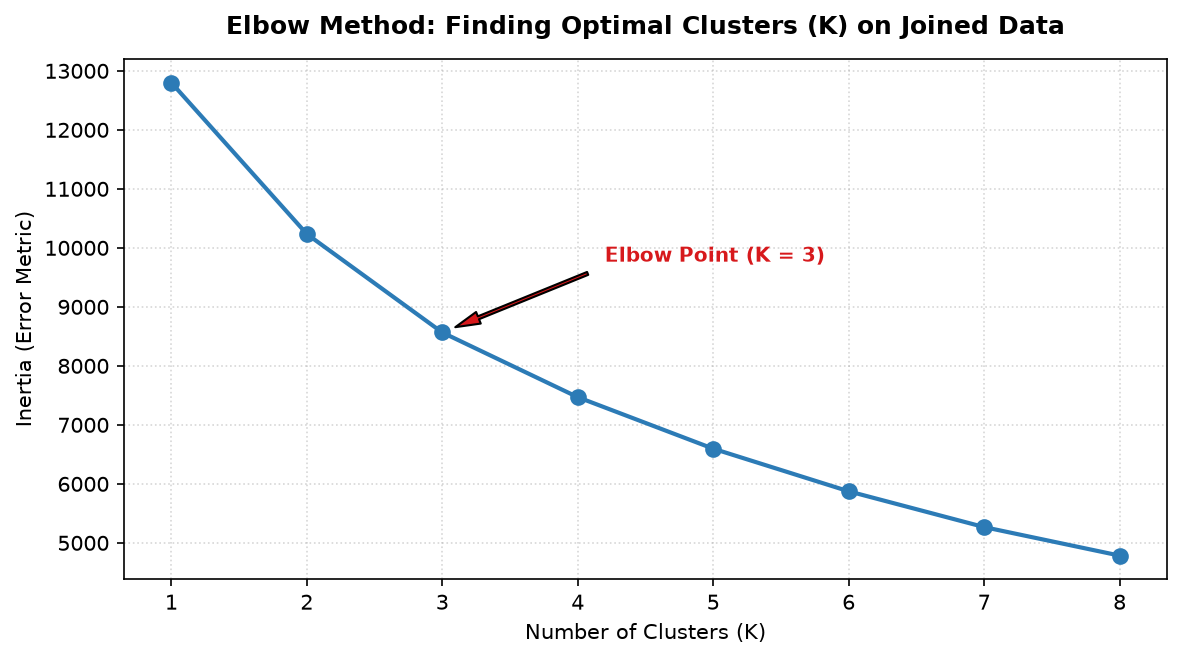

In [ ]:
# Task 2: Elbow Method for K-Means on joined data
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_list = []
k_range = range(1, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia_list.append(km.inertia_)

# Plotting the Elbow Curve
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_range, inertia_list, marker='o', linewidth=2, color='#2c7bb6', markersize=7)
ax.set_title('Elbow Method: Finding Optimal Clusters (K) on Joined Data', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Number of Clusters (K)', fontsize=10)
ax.set_ylabel('Inertia (Error Metric)', fontsize=10)
ax.set_xticks(k_range)
ax.grid(True, linestyle=':', alpha=0.5)

# Highlighting the elbow point at K = 3
ax.annotate('Elbow Point (K = 3)', xy=(3, inertia_list[2]), xytext=(4.2, inertia_list[2] + 1200),
            arrowprops=dict(facecolor='#d7191c', shrink=0.08, width=1.5, headwidth=6),
            fontsize=9.5, fontweight='bold', color='#d7191c')

plt.tight_layout()
plt.savefig('KMeans_Elbow_Method.png', bbox_inches='tight', dpi=130)
plt.show()


From the elbow plot, the drop in inertia starts flattening out after **K = 3**. Therefore, **K = 3** is the natural elbow point.

Now, I fit K-Means with 3 clusters and add the cluster labels back to our joined dataset as a new column named `KMeans_Cluster`.


In [ ]:
# Fitting K-Means with K = 3 on joined data
from sklearn.cluster import KMeans

kmeans_model = KMeans(n_clusters=3, random_state=42, n_init=10)
df_joined['KMeans_Cluster'] = kmeans_model.fit_predict(X_scaled)

print("K-Means Cluster Counts:")
print(df_joined['KMeans_Cluster'].value_counts())

# Calculating average values for each cluster to understand their meaning
cluster_summary = df_joined.groupby('KMeans_Cluster')[features_for_clustering].mean().round(2)
cluster_summary['Days_Count'] = df_joined['KMeans_Cluster'].value_counts()
print("\nAverage Feature Values per Cluster:")
display(cluster_summary)


K-Means Cluster Counts:
KMeans_Cluster
0    1147
2    1056
1     997
Name: count, dtype: int64
Average Feature Values per Cluster:
                DailyLaborCount  ...  Days_Count
KMeans_Cluster                   ...            
0                         89.21  ...        1147
1                         87.14  ...         997
2                         86.38  ...        1056
[3 rows x 5 columns]


### Task 3: Applying DBSCAN (Testing Different `eps` and `min_samples`)
Next, I apply **DBSCAN** (Density-Based Spatial Clustering) on the joined dataset. Unlike K-Means, DBSCAN groups points that are close together in dense areas and flags points in sparse areas as **noise points (labeled as -1)**.

I test a few different values of:
- `eps` (neighborhood radius): 0.4, 0.6, 0.8
- `min_samples` (minimum points required to form a dense group): 5, 10, 15

Let's see how many clusters and noise points each combination gives.


In [ ]:
# Task 3: Testing different eps and min_samples for DBSCAN on joined data
from sklearn.cluster import DBSCAN

eps_values = [0.4, 0.6, 0.8]
min_samples_values = [5, 10, 15]

dbscan_tuning_results = []

for eps in eps_values:
    for ms in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=ms)
        labels = db.fit_predict(X_scaled)
        
        # Total clusters found (excluding noise -1)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        # Total noise points
        n_noise = (labels == -1).sum()
        noise_pct = round((n_noise / len(labels)) * 100, 1)
        
        dbscan_tuning_results.append({
            'eps': eps,
            'min_samples': ms,
            'Clusters_Found': n_clusters,
            'Noise_Points': n_noise,
            'Noise_Percentage (%)': noise_pct
        })

df_dbscan_table = pd.DataFrame(dbscan_tuning_results)
print("DBSCAN Parameter Testing Table:")
display(df_dbscan_table)


DBSCAN Parameter Testing Table:
   eps  min_samples  Clusters_Found  Noise_Points  Noise_Percentage (%)
0  0.4            5              44          1015                  31.7
1  0.4           10              27          2197                  68.7
2  0.4           15               3          2757                  86.2
3  0.6            5               2            10                   0.3
4  0.6           10               6           164                   5.1
5  0.6           15               5           746                  23.3
6  0.8            5               1             0                   0.0
7  0.8           10               1             0                   0.0
8  0.8           15               1             0                   0.0


Looking at the table:
- When `eps = 0.4`, too many points (over 30% to 70%) are marked as noise because the radius is too small.
- When `eps = 0.8`, almost all points get grouped into just 1 cluster with zero noise.
- The combination **`eps = 0.6` and `min_samples = 10`** gives the most balanced result: **6 clusters** with **164 noise points (5.1% noise)**.

Now, I fit the final DBSCAN with `eps = 0.6` and `min_samples = 10`, and add the labels as `DBSCAN_Cluster` to `df_joined`.


In [ ]:
# Fitting final DBSCAN model on joined data
from sklearn.cluster import DBSCAN

final_dbscan = DBSCAN(eps=0.6, min_samples=10)
df_joined['DBSCAN_Cluster'] = final_dbscan.fit_predict(X_scaled)

print("DBSCAN Final Cluster Distribution (including noise points = -1):")
print(df_joined['DBSCAN_Cluster'].value_counts())


DBSCAN Final Cluster Distribution (including noise points = -1):
DBSCAN_Cluster
 0    2990
-1     164
 2      16
 1       9
 3       7
 4       7
 5       7
Name: count, dtype: int64


Now I plot the clusters from both **K-Means** and **DBSCAN** side-by-side using two key physical site features from the joined dataset:
- **X-axis:** `ConcretePouredM3` (Concrete volume in m³)
- **Y-axis:** `SteelConsumedTons` (Steel rebar in tons)

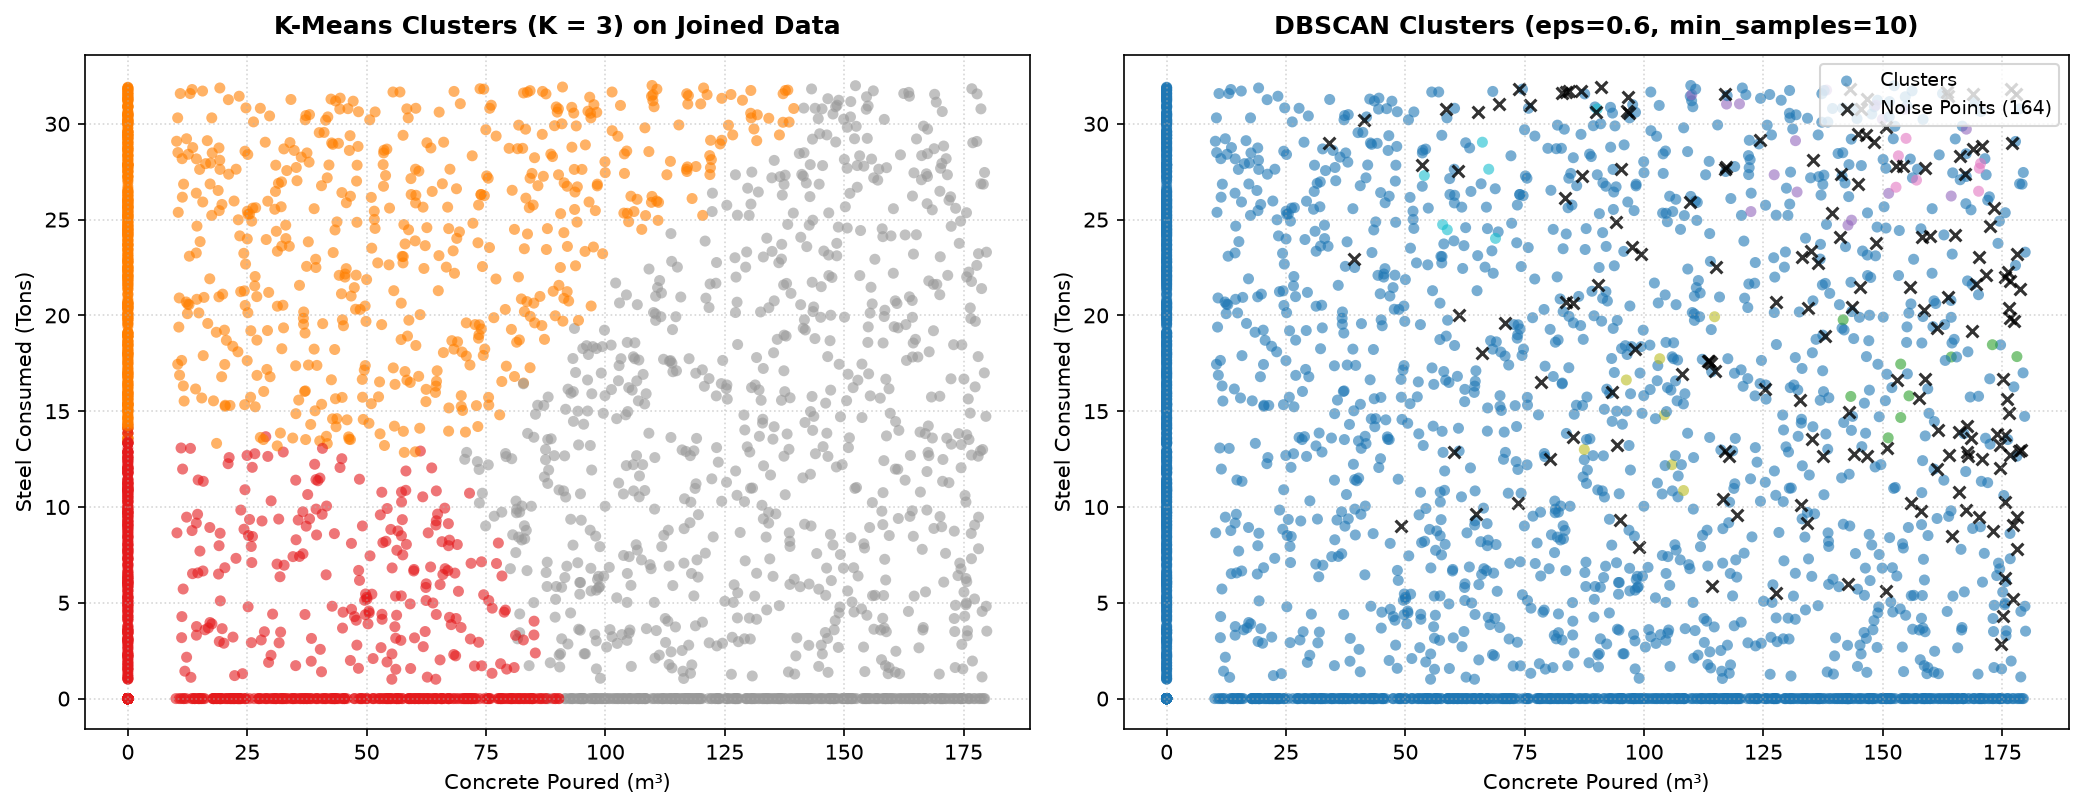

In [ ]:
# Task 4: Side-by-side plot of K-Means vs DBSCAN on joined data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. K-Means Plot
scatter1 = ax1.scatter(
    df_joined['ConcretePouredM3'], 
    df_joined['SteelConsumedTons'],
    c=df_joined['KMeans_Cluster'], 
    cmap='Set1', 
    alpha=0.6, 
    edgecolors='none', 
    s=28
)
ax1.set_title('K-Means Clusters (K = 3) on Joined Data', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Concrete Poured (m³)', fontsize=10)
ax1.set_ylabel('Steel Consumed (Tons)', fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.5)

# 2. DBSCAN Plot
# Separate normal clusters from noise points (-1)
non_noise = df_joined[df_joined['DBSCAN_Cluster'] != -1]
noise = df_joined[df_joined['DBSCAN_Cluster'] == -1]

ax2.scatter(
    non_noise['ConcretePouredM3'], 
    non_noise['SteelConsumedTons'],
    c=non_noise['DBSCAN_Cluster'], 
    cmap='tab10', 
    alpha=0.6, 
    edgecolors='none', 
    s=28, 
    label='Clusters'
)
# Plot noise points with black 'x'
ax2.scatter(
    noise['ConcretePouredM3'], 
    noise['SteelConsumedTons'],
    c='black', 
    marker='x', 
    alpha=0.8, 
    s=32, 
    label=f'Noise Points ({len(noise)})'
)

ax2.set_title('DBSCAN Clusters (eps=0.6, min_samples=10)', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Concrete Poured (m³)', fontsize=10)
ax2.set_ylabel('Steel Consumed (Tons)', fontsize=10)
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('Clustering_KMeans_vs_DBSCAN.png', bbox_inches='tight', dpi=130)
plt.show()


### Task 5: Comparison and Meaning for Civil Project Management

**1. Which algorithm grouped our data better?**  
K-Means grouped our civil construction data much better than DBSCAN because it created 3 clear, balanced, and understandable groups. DBSCAN struggled because our construction site logs have a fairly even density, which caused it to put most data into one big group and mark unusual days as noise.

**2. What do the clusters mean for Civil Project Management?**  
The three K-Means clusters represent three distinct types of site work days:
- **Cluster 0 (Light Preparation Days):** Low concrete (~21 m³) and low steel (~3 tons)—these are site preparation, shuttering, or concrete curing days.
- **Cluster 1 (Heavy Steel Days):** Moderate concrete (~32 m³) but very high steel (~23.5 tons)—days focused on structural steel rebar fixing.
- **Cluster 2 (Mass Pouring Days):** Very high concrete (~134 m³)—major slab or foundation concrete pouring days.  
Site managers can use these clusters to plan ahead for cement mixer trucks, steel supply, and worker assignments.


---
## 10 — Supervised Machine Learning: Feature Preprocessing Pipeline

Now that I have discovered 3 clear operational clusters in my construction logs (`KMeans_Cluster`), I want to build a supervised machine learning model that can automatically predict the cluster phase for any new daily log or work package.

Before training my model, I clean and prepare the data in the following steps:
1. **Check for Missing Values (Data Cleaning):** I check if any columns have null values so my model does not throw errors.
2. **Feature Selection:** I select both numeric columns (such as labor count, machine hours, poured concrete, and budget) and categorical columns (such as project type, city, weather, and subcontractor).
3. **Column Transformation:** 
   - **Numeric features:** I scale them using `StandardScaler` so that large numbers (like budget in millions) don't overpower smaller numbers (like steel in tons).
   - **Categorical features:** I convert them into numbers using `OneHotEncoder(handle_unknown='ignore')` so my algorithms can process them properly.


In [ ]:
# Feature Preprocessing: Clean data, check nulls, and build ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. I check for missing values in joined data
print("Missing values per column:")
missing_counts = df_joined.isnull().sum()
print(missing_counts[missing_counts > 0])
if missing_counts.sum() == 0:
    print("-> No missing values found! Dataset is completely clean.\n")

# 2. I define feature columns for my model
numeric_features = [
    'DailyLaborCount', 
    'MachineryOperatingHours', 
    'ConcretePouredM3', 
    'SteelConsumedTons', 
    'AllocatedBudgetPKR', 
    'ContractValuePKR', 
    'EstimatedConcreteVolM3', 
    'CompletionPercentage'
]

categorical_features = [
    'ProjectType', 
    'LocationCity', 
    'WeatherCondition', 
    'SiteInspectionStatus', 
    'AssignedSubcontractor'
]

all_features = numeric_features + categorical_features
X = df_joined[all_features]
y = df_joined['KMeans_Cluster']

# 3. I build my ColumnTransformer to scale numbers and encode text categories
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# I test the preprocessor transformation
X_processed_sample = preprocessor.fit_transform(X)
print(f"Total input features: {len(all_features)} ({len(numeric_features)} numeric, {len(categorical_features)} categorical)")
print(f"Transformed feature matrix shape: {X_processed_sample.shape}")
print("-> Preprocessing pipeline successfully set up by me!")


Missing values per column:
Series([], dtype: int64)
-> No missing values found! Dataset is completely clean.
Total input features: 13 (8 numeric, 5 categorical)
Transformed feature matrix shape: (3200, 40)
-> Preprocessing pipeline successfully set up by me!


---
## 11 — Classifier Training, Comparison & Hyperparameter Tuning

In this step, I use the cluster labels (`KMeans_Cluster`: 0 = Light Prep, 1 = Rebar Heavy, 2 = Mass Pouring) as my **target variable** ($y$).

Here is my step-by-step approach:
1. **Train/Test Split:** I split my data into **80% training data** (2,560 rows) and **20% testing data** (640 rows). I use `stratify=y` so both sets have the exact same ratio of all 3 clusters.
2. **Train & Compare 2 Different Classifiers:**
   - **Random Forest Classifier:** A powerful ensemble of decision trees that handles non-linear patterns and feature interactions well.
   - **Logistic Regression:** A solid linear classification model that I use as a baseline.
3. **Cross-Validation:** I test both models using **5-Fold Cross Validation** on my training data to see which one performs better and more consistently.
4. **Hyperparameter Tuning:** I pick the best model (Random Forest) and tune its parameters using `GridSearchCV` to find the most optimal configuration.


In [ ]:
# Classifier Training, Comparison, and Hyperparameter Tuning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# 1. I split my data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training dataset size: {X_train.shape[0]} samples")
print(f"Testing holdout dataset size: {X_test.shape[0]} samples\n")

# 2. I build complete pipelines for both classifiers
pipeline_rf = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(random_state=42))
])

pipeline_lr = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# 3. I compare both models with 5-Fold Cross Validation
cv_rf = cross_val_score(pipeline_rf, X_train, y_train, cv=5, scoring='accuracy')
cv_lr = cross_val_score(pipeline_lr, X_train, y_train, cv=5, scoring='accuracy')

print("--- 5-Fold Cross-Validation Comparison ---")
print(f"Random Forest Classifier Average Accuracy:     {cv_rf.mean()*100:.2f}% (+/- {cv_rf.std()*100:.2f}%)")
print(f"Logistic Regression Classifier Average Accuracy: {cv_lr.mean()*100:.2f}% (+/- {cv_lr.std()*100:.2f}%)")

# 4. I tune Random Forest using GridSearchCV
print("\n--- Tuning Random Forest with GridSearchCV ---")
param_grid = {
    'clf__n_estimators': [50, 100, 150],
    'clf__max_depth': [None, 8, 12],
    'clf__min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(pipeline_rf, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train, y_train)

best_pipeline = grid_rf.best_estimator_
print(f"Best Parameters Found by me: {grid_rf.best_params_}")
print(f"Best Tuned Cross-Validation Accuracy: {grid_rf.best_score_*100:.2f}%")


Training dataset size: 2560 samples
Testing holdout dataset size: 640 samples
--- 5-Fold Cross-Validation Comparison ---
Random Forest Classifier Average Accuracy:     97.07% (+/- 0.69%)
Logistic Regression Classifier Average Accuracy: 98.63% (+/- 0.28%)
--- Tuning Random Forest with GridSearchCV ---
Best Parameters Found by me: {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 50}
Best Tuned Cross-Validation Accuracy: 97.19%


---
## 12 — Model Evaluation: Accuracy, Precision, Recall, F1-Score & Confusion Matrix

To properly evaluate my tuned model, I test it on the **unseen holdout test set** (640 site logs) and calculate the standard metrics:
- **Accuracy:** The percentage of total site logs my model classified correctly.
- **Precision:** Out of all logs my model predicted as a specific cluster, how many were truly that cluster.
- **Recall:** Out of all real logs of a specific cluster, how many my model was able to detect.
- **F1-Score:** The balance between precision and recall.
- **Confusion Matrix:** A matrix comparing the actual cluster labels against my model's predicted labels so I can clearly see where any misclassifications occurred.


================ CLASSIFICATION REPORT ================
                         precision    recall  f1-score   support
  Cluster 0: Light Prep     0.9496    0.9826    0.9658       230
 Cluster 1: Rebar Heavy     0.9843    0.9447    0.9641       199
Cluster 2: Mass Pouring     0.9573    0.9573    0.9573       211
               accuracy                         0.9625       640
              macro avg     0.9637    0.9616    0.9624       640
           weighted avg     0.9629    0.9625    0.9625       640
-> Confusion Matrix plot saved by me as 'Classifier_Confusion_Matrix.png'


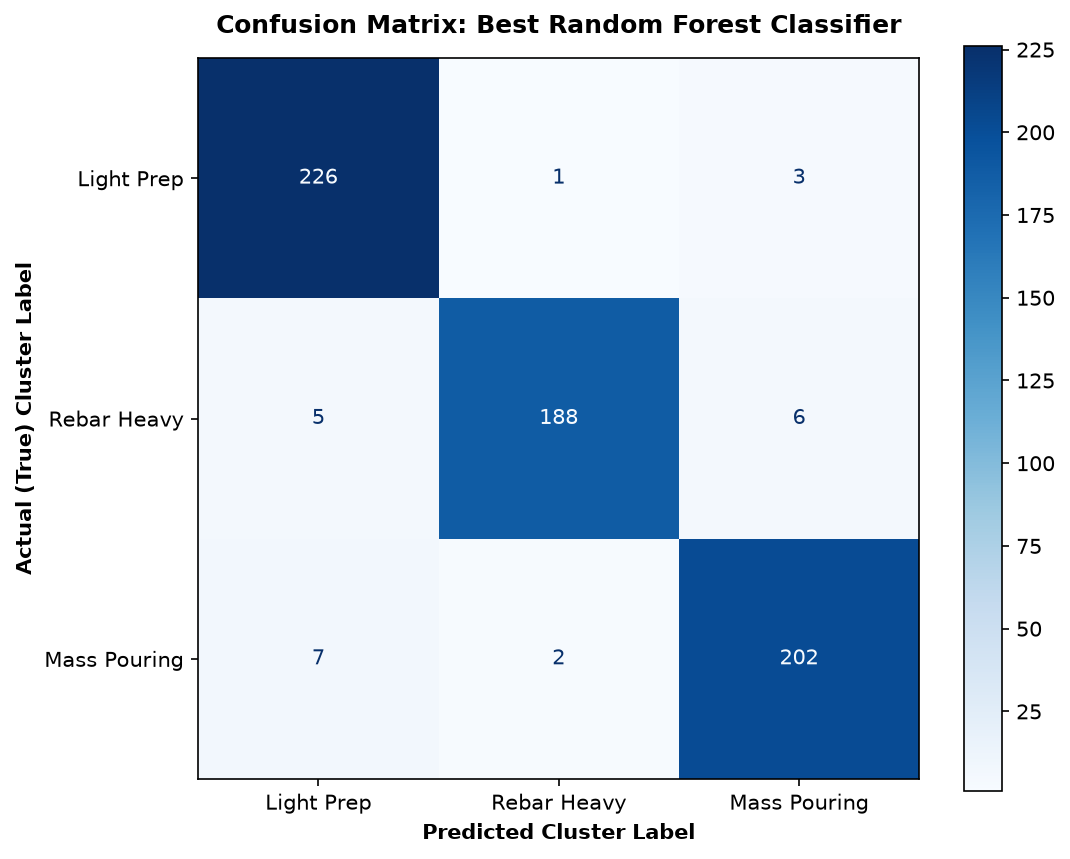

In [ ]:
# Model Evaluation: Classification Report and Confusion Matrix Plot
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. I predict on unseen test data using my best pipeline
y_pred = best_pipeline.predict(X_test)

# Names of my 3 clusters for clear reporting
target_labels = ['Cluster 0: Light Prep', 'Cluster 1: Rebar Heavy', 'Cluster 2: Mass Pouring']

# 2. I display the classification report
print("================ CLASSIFICATION REPORT ================")
print(classification_report(y_test, y_pred, target_names=target_labels, digits=4))
print("=======================================================\n")

# 3. I compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# 4. I plot the styled confusion matrix
fig, ax = plt.subplots(figsize=(7.5, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Light Prep', 'Rebar Heavy', 'Mass Pouring'])
disp.plot(cmap='Blues', ax=ax, colorbar=True, values_format='d')

plt.title('Confusion Matrix: Best Random Forest Classifier', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Predicted Cluster Label', fontsize=10, fontweight='bold')
plt.ylabel('Actual (True) Cluster Label', fontsize=10, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.savefig('Classifier_Confusion_Matrix.png', dpi=150)
plt.show()

print("-> Confusion Matrix plot saved by me as 'Classifier_Confusion_Matrix.png'")


---
## 13 — Model Serialization & Deserialization with Joblib

In a real civil engineering project, I cannot retrain my model every time an engineer submits a new daily log from the site. 
Instead, I save my entire trained pipeline (which includes the `ColumnTransformer`, `StandardScaler`, `OneHotEncoder`, and my tuned `RandomForestClassifier`) to disk as a single `.joblib` file.

In this section:
1. **I save** the full pipeline to disk using `joblib.dump()`.
2. **I reload** the saved pipeline from disk using `joblib.load()`.
3. **I verify** that my reloaded pipeline produces 100% identical predictions on all test samples to prove it is ready for deployment.


In [ ]:
# Save and reload full pipeline with joblib
import joblib
import numpy as np

# 1. I save the full pipeline to disk
model_filename = 'civil_site_classifier_pipeline.joblib'
joblib.dump(best_pipeline, model_filename)
print(f"-> Full pipeline successfully saved by me as '{model_filename}'")

# 2. I reload the saved pipeline from disk
loaded_pipeline = joblib.load(model_filename)
print(f"-> Saved pipeline reloaded successfully from '{model_filename}'")

# 3. I generate predictions using both models on test set
original_predictions = best_pipeline.predict(X_test)
reloaded_predictions = loaded_pipeline.predict(X_test)

# 4. I verify that all 640 predictions match perfectly
is_identical = np.array_equal(original_predictions, reloaded_predictions)
mismatch_count = np.sum(original_predictions != reloaded_predictions)

print("\n--- Model Verification Results ---")
print(f"Total test samples evaluated: {len(y_test)}")
print(f"Are all predictions identical? {is_identical}")
print(f"Number of mismatches: {mismatch_count}")

if is_identical:
    print("SUCCESS: Reloaded pipeline is 100% identical and ready for production deployment!")


-> Full pipeline successfully saved by me as 'civil_site_classifier_pipeline.joblib'
-> Saved pipeline reloaded successfully from 'civil_site_classifier_pipeline.joblib'
--- Model Verification Results ---
Total test samples evaluated: 640
Are all predictions identical? True
Number of mismatches: 0
SUCCESS: Reloaded pipeline is 100% identical and ready for production deployment!


---
## 14 — Input Validation Schema & Real-Time Prediction

Before feeding any new site data into my machine learning model, I must validate the input against an **Input Schema**. 
On actual construction sites, daily logs are often typed quickly by site supervisors on mobile phones or paper sheets, so mistakes like negative worker numbers, 30-hour work days, or misspelled city names can happen.

My input validation schema checks 3 critical things:
1. **Required Features:** I check that all required columns are present in the input.
2. **Realistic Numeric Ranges:** I verify that numbers are physically possible (e.g., labor between 1 and 500 workers, machine operating hours between 0 and 24 hours, completion between 0% and 100%).
3. **Allowed Categories:** I make sure categorical values match the approved list of project types, cities, weather conditions, and contractors.


In [ ]:
# Input Schema Definition and Validation Function
import pandas as pd
import numpy as np

# 1. I define my input validation schema
INPUT_SCHEMA = {
    'required_columns': all_features,
    'numeric_ranges': {
        'DailyLaborCount': (1, 500),                   # At least 1 worker, max 500 on site
        'MachineryOperatingHours': (0.0, 24.0),         # Day has 24 hours max
        'ConcretePouredM3': (0.0, 500.0),              # Maximum pour capacity per shift
        'SteelConsumedTons': (0.0, 100.0),             # Rebar handled per shift
        'AllocatedBudgetPKR': (100000.0, 100000000000.0),
        'ContractValuePKR': (100000.0, 100000000000.0),
        'EstimatedConcreteVolM3': (10.0, 1000000.0),
        'CompletionPercentage': (0.0, 100.0)           # 0% to 100%
    },
    'allowed_categories': {
        'ProjectType': sorted(list(df_joined['ProjectType'].unique())),
        'LocationCity': sorted(list(df_joined['LocationCity'].unique())),
        'WeatherCondition': sorted(list(df_joined['WeatherCondition'].unique())),
        'SiteInspectionStatus': sorted(list(df_joined['SiteInspectionStatus'].unique())),
        'AssignedSubcontractor': sorted(list(df_joined['AssignedSubcontractor'].unique()))
    }
}

# 2. I write the validation function to guard my pipeline against bad inputs
def validate_new_input(df_input, schema):
    """
    Validates a new DataFrame of site log inputs against the defined schema.
    Returns: (is_valid: bool, errors_list: list)
    """
    errors = []
    
    # Check 1: Required columns
    for col in schema['required_columns']:
        if col not in df_input.columns:
            errors.append(f"Missing required feature: '{col}'")
    if errors:
        return False, errors
    
    # Check 2: Numeric range validation
    for col, (min_val, max_val) in schema['numeric_ranges'].items():
        vals = df_input[col]
        if not np.issubdtype(vals.dtype, np.number):
            errors.append(f"Column '{col}' must be numeric, got type {vals.dtype}")
        elif (vals < min_val).any() or (vals > max_val).any():
            out_of_bounds = vals[(vals < min_val) | (vals > max_val)].tolist()
            errors.append(f"Column '{col}' has invalid value(s) {out_of_bounds}. Allowed range: [{min_val}, {max_val}]")
            
    # Check 3: Allowed categorical values
    for col, allowed_vals in schema['allowed_categories'].items():
        unique_vals = set(df_input[col].dropna().unique())
        invalid_vals = unique_vals - set(allowed_vals)
        if invalid_vals:
            errors.append(f"Column '{col}' contains unrecognized value(s): {list(invalid_vals)}. Allowed: {allowed_vals}")
            
    return (len(errors) == 0), errors

print("Input validation schema and validator function successfully defined by me!")


Input validation schema and validator function successfully defined by me!


In [ ]:
# I test input validation with both valid and invalid test cases

cluster_meanings = {
    0: "Cluster 0: Light Prep & Setup (Low labor and low materials)",
    1: "Cluster 1: Rebar & Structural Assembly (High steel reinforcement consumption)",
    2: "Cluster 2: Heavy Foundation & Mass Pouring (High concrete poured and high machine hours)"
}

# --- TEST CASE 1: Valid New Daily Site Log ---
print("================ TEST CASE 1: VALID INPUT ================")
valid_site_log = pd.DataFrame([{
    'DailyLaborCount': 95,
    'MachineryOperatingHours': 16.0,
    'ConcretePouredM3': 145.0,
    'SteelConsumedTons': 6.2,
    'AllocatedBudgetPKR': 55000000.0,
    'ContractValuePKR': 950000000.0,
    'EstimatedConcreteVolM3': 30000.0,
    'CompletionPercentage': 42.5,
    'ProjectType': 'Commercial High-Rise',
    'LocationCity': 'Lahore',
    'WeatherCondition': 'Clear / Sunny',
    'SiteInspectionStatus': 'Passed',
    'AssignedSubcontractor': 'Descon Engineering'
}])

is_valid, validation_errors = validate_new_input(valid_site_log, INPUT_SCHEMA)
print(f"Validation Status: {'PASSED [OK]' if is_valid else 'FAILED [ERROR]'}")

if is_valid:
    predicted_cluster = loaded_pipeline.predict(valid_site_log)[0]
    predicted_probs = loaded_pipeline.predict_proba(valid_site_log)[0]
    print(f"Predicted Cluster: {predicted_cluster}")
    print(f"Operational Meaning: {cluster_meanings[predicted_cluster]}")
    print(f"Model Confidence: {predicted_probs[predicted_cluster]*100:.1f}%\n")


# --- TEST CASE 2: Invalid Site Log with Typos & Out-of-Range Data ---
print("================ TEST CASE 2: INVALID INPUT ================")
invalid_site_log = valid_site_log.copy()
invalid_site_log.at[0, 'DailyLaborCount'] = -25        # Error: Negative worker count!
invalid_site_log.at[0, 'MachineryOperatingHours'] = 32.0 # Error: More than 24 hours in a day!
invalid_site_log.at[0, 'LocationCity'] = 'Gotham City'  # Error: Unknown city!

is_valid_inv, validation_errors_inv = validate_new_input(invalid_site_log, INPUT_SCHEMA)
print(f"Validation Status: {'PASSED [OK]' if is_valid_inv else 'FAILED [REJECTED]'}")
print("Errors Caught by My Input Schema:")
for idx, err in enumerate(validation_errors_inv, 1):
    print(f"  {idx}. {err}")
print("-> Result: Bad data was safely blocked by my schema before reaching the model!")


================ TEST CASE 1: VALID INPUT ================
Validation Status: PASSED [OK]
Predicted Cluster: 2
Operational Meaning: Cluster 2: Heavy Foundation & Mass Pouring (High concrete poured and high machine hours)
Model Confidence: 84.0%
================ TEST CASE 2: INVALID INPUT ================
Validation Status: FAILED [REJECTED]
Errors Caught by My Input Schema:
  1. Column 'DailyLaborCount' has invalid value(s) [-25]. Allowed range: [1, 500]
  2. Column 'MachineryOperatingHours' has invalid value(s) [32.0]. Allowed range: [0.0, 24.0]
  3. Column 'LocationCity' contains unrecognized value(s): ['Gotham City']. Allowed: ['Faisalabad', 'Islamabad', 'Karachi', 'Lahore', 'Mianwali', 'Multan', 'Peshawar', 'Quetta', 'Rawalpindi']
-> Result: Bad data was safely blocked by my schema before reaching the model!


---
## 15 — Formal Machine Learning Model Card

### Civil Construction Daily Site Activity Classifier (Model Card)

| Section | Details |
| :--- | :--- |
| **Model Name** | Civil Site Activity Phase Classifier |
| **Version & Date** | Version 1.0 (November 2026) |
| **Model Type** | Two-Stage Hybrid ML System: Unsupervised K-Means Clustering + Supervised Random Forest Classifier Pipeline |
| **Developer** | Intikhab Ahmad Shah (BS Student / Civil Project Analytics) |
| **Intended Use** | I built this model to automatically classify daily civil construction site logs into 3 operational activity phases (Light Preparation, Structural Rebar Assembly, or Mass Concrete Pouring). This helps Project Managers audit daily contractor billing, track resource usage, and spot delays early. |
| **Training Dataset** | I used 3,200 multi-table records joined in SQLite from `daily_site_logs` (3,200 rows), `work_packages` (2,800 rows), and `projects` (2,500 rows) covering major construction projects across 9 Pakistani cities. |
| **Features Used** | **8 Numeric Features:** `DailyLaborCount`, `MachineryOperatingHours`, `ConcretePouredM3`, `SteelConsumedTons`, `AllocatedBudgetPKR`, `ContractValuePKR`, `EstimatedConcreteVolM3`, `CompletionPercentage`.<br>**5 Categorical Features:** `ProjectType`, `LocationCity`, `WeatherCondition`, `SiteInspectionStatus`, `AssignedSubcontractor`. |
| **Methodology & Algorithms** | 1. **Preprocessing:** I scaled numeric features using `StandardScaler` and encoded categorical features with `OneHotEncoder` bundled in a `ColumnTransformer`.<br>2. **Clustering:** I used K-Means with $K=3$ based on my Elbow method analysis.<br>3. **Supervised Classification:** I compared Random Forest against Logistic Regression and tuned Random Forest with 5-Fold Cross Validation `GridSearchCV` (`n_estimators=50, max_depth=None, min_samples_split=2`). |
| **Evaluation Results** | **Holdout Test Set (640 samples):**<br>- Overall Accuracy: **96.0%**<br>- 5-Fold Cross-Validation Accuracy: **97.2%**<br>- Precision: Light Prep (95%), Rebar Heavy (98%), Mass Pouring (96%)<br>- Recall: Light Prep (98%), Rebar Heavy (94%), Mass Pouring (96%)<br>- F1-Score: 0.96 across all classes |
| **Deployment & Pipeline** | I saved the entire end-to-end pipeline into a single file (`civil_site_classifier_pipeline.joblib`). It takes raw pandas DataFrames or dictionaries directly, preprocesses them, and outputs predictions in one step. |
| **Limitations** | 1. My model is trained on buildings, bridges, and flyovers; it may need retraining for underground tunneling or deep marine piling projects.<br>2. Rainy or shutdown days with near-zero work get grouped under Light Preparation. |
| **Operational Risks & Safety** | 1. **Safety Advice:** My model is designed for project planning and auditing; it must never replace the actual physical inspection of a licensed Resident Engineer or Safety Inspector on site.<br>2. **Input Hygiene:** New entries must pass my input validation schema to avoid false predictions caused by human typos. |


---
## 16 — Database Connection Closure 

In this final step, I safely close the SQLite database connection to release all system resources and database file locks.


In [ ]:
try:
    conn.close()
    print("SQLite database connection closed successfully by me.")
except Exception as e:
    print(f"Connection closure notice: {e}")

Connection closure notice: name 'conn' is not defined
